In [2]:
import heapq, itertools

In [3]:
def reconstruct_path(path, current):
    total_path = [current]
    while path[current] != None:
        current = path[current]
        total_path.append(current)
    total_path.reverse()
    return total_path

def a_star(graph, h, s, t):
    priority_queue = [(h[s], s)]
    path = {s: None}
    g = {s: 0}
    steps = []

    while priority_queue:
        x, node = heapq.heappop(priority_queue)

        if node == t:
            return x, reconstruct_path(path, node), steps

        for neighbor, weight in graph[node].items():
            new_g = g[node] + weight
            if new_g < g.get(neighbor, float("inf")):
                path[neighbor] = node
                g[neighbor] = new_g
                heapq.heappush(priority_queue, (new_g + h[neighbor], neighbor))

        steps.append(dict(current=node, g=dict(g), queue=sorted((f, n) for f, n in priority_queue)))
    
    return None, None, steps

In [4]:
graph = {
    "s": {"d": 3, "a": 2},
    "a": {"d": 1, "b": 1},
    "d": {"c": 7, "b": 2},
    "b": {"c": 8, "t": 10},
    "c": {"t": 1 },
    "t": {}
}

h = {
    "s": 10,
    "d": 7,
    "a": 3,
    "b": 2,
    "c": 1,
    "t": 0
}

pos = {
    "s": (0, 1),
    "d": (1.5, 2),
    "a": (1, 0),
    "b": (2, 0.5),
    "c": (3, 1.2),
    "t": (4, 1)
}

In [5]:
import networkx as nx
import matplotlib.pyplot as plt

In [6]:
G = nx.Graph()
for node, neighbors in graph.items():
    for neighbor, weight in neighbors.items():
        G.add_edge(node, neighbor, weight=weight)

In [7]:
def draw_step(step, path):
    in_queue = { n for _, n in step["queue"]}
    colors = []
    for n in G.nodes:
        if n == step["current"]: colors.append("green")
        elif n in in_queue: colors.append("orange")
        else: colors.append("white")

    fig, ax = plt.subplots(figsize=(6, 4))
    nx.draw_networkx_edges(G, pos, ax=ax)
    nx.draw_networkx_nodes(G, pos, node_color=colors, edgecolors="black", node_size = 900, ax=ax)
    nx.draw_networkx_labels(G, pos, ax=ax)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"), ax = ax)

    #h
    pos_above = {n: (x - 0.25, y + 0.25) for n, (x, y) in pos.items()}
    h_labels = {n: f"h={h[n]}" for n in G.nodes}
    nx.draw_networkx_labels(G, pos_above, labels=h_labels, font_size=9, font_color="blue", ax=ax)
    
    queue_text = "\n".join(f"vertex={n} costs={f}" for f, n in step["queue"]) or ""
    path_text = "\n".join(f"vertex={n}" for n in path) or ""
    
    ax.text(1, 0.5, "Priority Queue:\n" + queue_text, transform = ax.transAxes, va="center")
    ax.text(1.5, 0.5, "Path:\n" + path_text, transform = ax.transAxes, va="center")
    ax.set_title(f"Current: {step['current']}")
    ax.axis("off")
    ax.margins(x=0.25, y=0.25)
    plt.show()

In [8]:
least_cost, path, steps = a_star(graph, h, "s", "t")

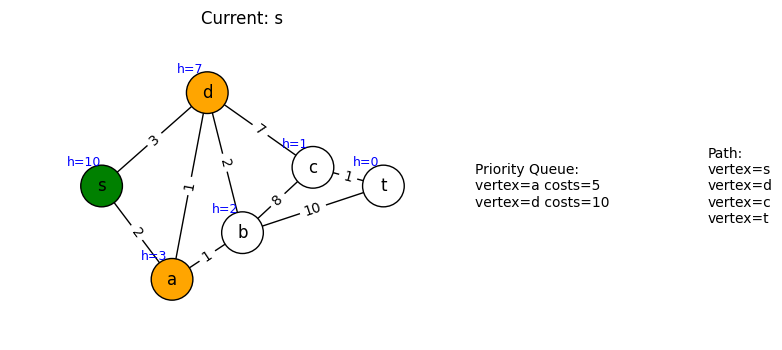

In [9]:
draw_step(steps[0], path)

In [10]:
#%pip install ipywidgets
#%pip install -U ipywidgets jupyterlab

In [11]:
from ipywidgets import interact
interact(lambda i: draw_step(steps[i], path), i=(0, len(steps) - 1))

interactive(children=(IntSlider(value=2, description='i', max=4), Output()), _dom_classes=('widget-interact',)…

<function __main__.<lambda>(i)>

In [12]:
least_cost

11